# 连锁餐饮门店经营数据分析
## 项目背景
本次样本为连锁品牌24家门店经营数据，门店之间利润率差异巨大，存在部分门店持续亏损、盈利门店梯队分化明显的问题。

## 分析目标
1. Q1：利润梯队如何分布？哪些门店处于亏损状态？亏损门店和盈利门店的成本结构差异在哪？
2. Q2：哪些指标和利润率相关性最强？人工率、房租率、翻台率对利润的影响程度？
3. Q3：基于数据给出可落地的门店优化建议，优先改善亏损门店。

## 结论摘要
1. 门店利润率与人工率呈现极强负相关（r=-0.85），人工成本占收入比重是决定门店盈亏的核心变量。
2. 亏损门店的人工率、房租率显著高于盈利门店，人力成本管控压力远大于优惠活动带来的影响。
3. 改善优先级：先针对高人工率亏损门店优化排班、人效，其次控制房租成本，配套提升翻台拉动营收。

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']   # 黑体，Windows自带
plt.rcParams['axes.unicode_minus'] = False

## 数据读取与预处理
读取脱敏后的门店经营数据，清洗百分比字段，衍生人工率、房租率、优惠率等分析指标。

In [3]:
row=pd.read_csv(r'D:\pandasproject\data\门店经营数据_脱敏.csv',encoding='utf8')
row.shape

(24, 18)

In [4]:
df=row.copy()
df.columns=df.columns.str.strip()
pct_cols=['毛利率','利润率']
for c in pct_cols:
    df[c]=df[c].astype(str).str.replace('%','',regex=False).astype(float)
df=df[df['一、主营业务收入']>0]

In [5]:
df['人工率']=df['人工成本合计']/df['一、主营业务收入']*100
df['房租率']=df['租赁费']/df['一、主营业务收入']*100
df['优惠率']=df['优惠金额']/df['一、主营业务收入']*100
df['外卖占比']=df['餐费收入-外送']/df['一、主营业务收入']*100
df['人工每桌']=df['人工成本合计']/df['总桌数']
keep=['月份','收银店名','一、主营业务收入','翻台率','毛利率','利润率','人工率','房租率','优惠率','外卖占比','人工每桌']
ana=df[keep].rename(columns={'收银店名':'门店','一、主营业务收入':'收入'})

## Q1 利润梯队：哪些门店在亏损？盈亏门店成本对比

In [6]:
tier=ana.sort_values('利润率',ascending=False)
tier.head(5)
tier[tier['利润率']<0]

,月份,门店,收入,翻台率,毛利率,利润率,人工率,房租率,优惠率,外卖占比,人工每桌
13,2026-02,门店U,1041604.10,0.88,56.78,-3.01,22.315010,10.752775,13.796555,28.814344,75.884447
18,2026-02,门店G,630095.86,1.09,58.69,-3.36,23.372315,6.600021,17.067851,56.774531,51.672979
3,2026-02,门店K,475456.44,1.14,55.69,-7.93,23.283008,17.285310,18.882380,30.811876,60.065415
20,2026-02,门店I,525761.45,1.25,57.25,-10.87,24.802476,6.044869,19.165118,46.743984,55.870548


## Q2 相关性分析：人工率与利润率关系可视化

In [7]:
loss=tier[tier['利润率']<0]
have=tier[tier['利润率']>0]
cmp=pd.DataFrame({'全组平均':ana[['人工率','房租率','优惠率']].mean().round(1),
                  '盈利店平均':have[['人工率','房租率','优惠率']].mean().round(1),
                  '亏损店平均':loss[['人工率','房租率','优惠率']].mean().round(1)})
cmp['亏损店超出']=(cmp['亏损店平均']-cmp['全组平均']).round(1)
cmp

,全组平均,盈利店平均,亏损店平均,亏损店超出
人工率,20.2,19.6,23.4,3.2
房租率,6.1,5.3,10.2,4.1
优惠率,15.8,15.6,17.2,1.4


### 盈亏门店成本对比解读
亏损门店人工率、房租率均值明显高于全组平均，优惠率差距很小，说明亏损主因不是打折促销，而是固定人力和房租成本过高。

In [8]:
for c in ['翻台率','人工率','房租率','优惠率','外卖占比']:
    r=ana['利润率'].corr(ana[c])
    print(f'利润率 vs {c}:r={r:.2f}')

利润率 vs 翻台率:r=0.74
利润率 vs 人工率:r=-0.85
利润率 vs 房租率:r=-0.63
利润率 vs 优惠率:r=-0.56
利润率 vs 外卖占比:r=-0.20


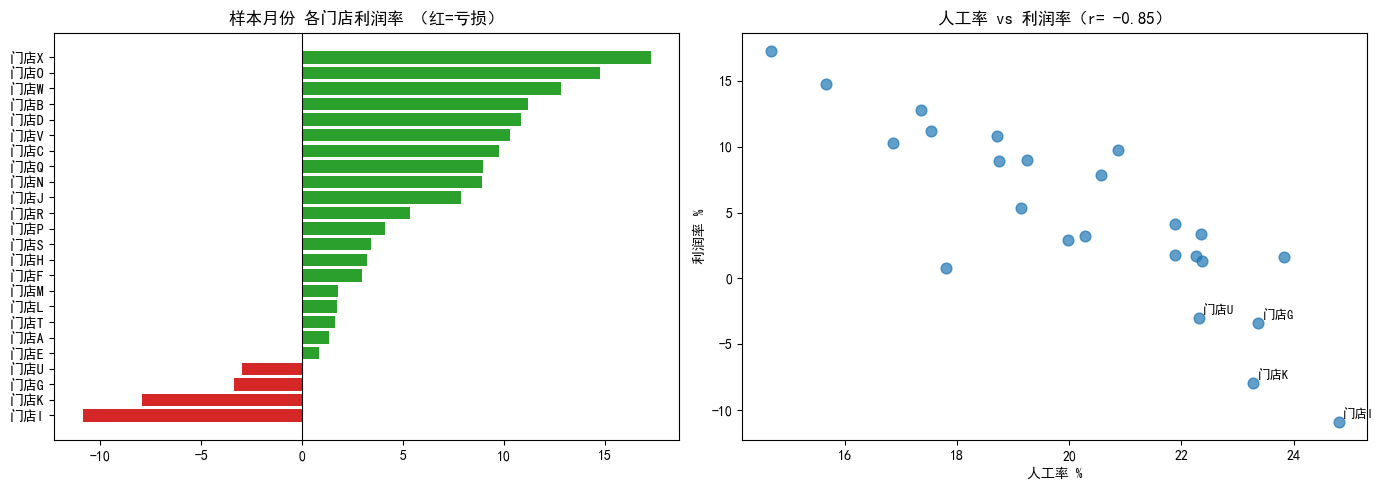

In [9]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
t=ana.sort_values('利润率')
colors=['#d62728' if x <0 else '#2ca02c' for x in t['利润率']]
axes[0].barh(t['门店'],t['利润率'],color=colors)
axes[0].set_title('样本月份 各门店利润率 （红=亏损）')
axes[0].axvline(0,color='black',linewidth=0.8)

axes[1].scatter(ana['人工率'],ana['利润率'],s=60,alpha=0.7)
axes[1].set_xlabel('人工率 %');axes[1].set_ylabel('利润率 %')
axes[1].set_title('人工率 vs 利润率（r= -0.85）')

loss_shop = ana[ana['利润率'] < 0]
for idx, row in loss_shop.iterrows():
    axes[1].annotate(
        row['门店'],
        xy=(row['人工率'], row['利润率']),
        xytext=(3,3),
        textcoords='offset points',
        fontsize=9
    )

plt.tight_layout()
plt.show()

### 图表解读
左侧横向条形图展示全部门店利润率梯队，共4家门店利润率小于0，处于亏损状态。 右侧散点图印证人工率与利润率强负相关，亏损门店全部落在人工率偏高的区间，人力成本侵蚀利润明显。

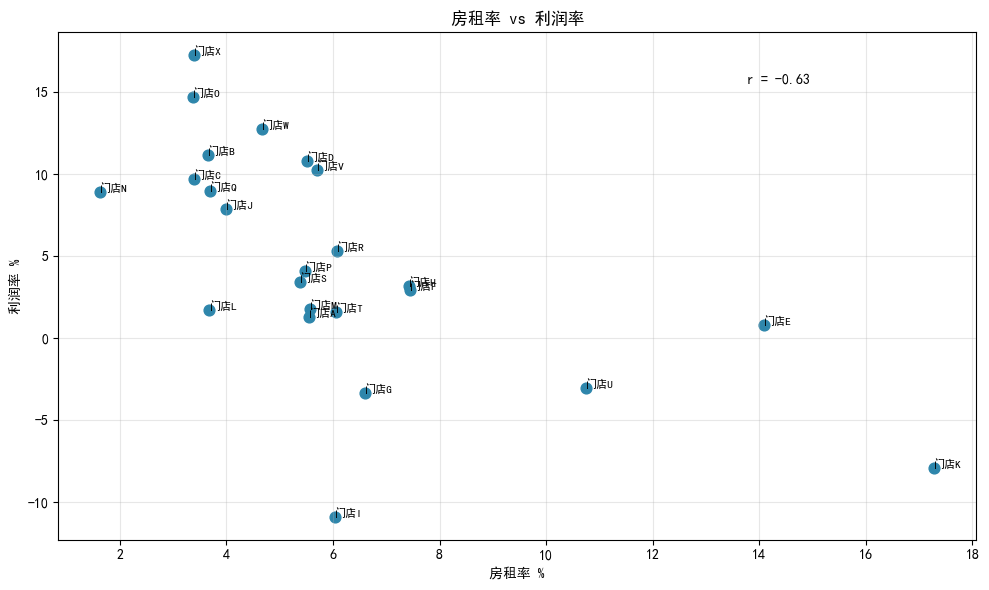

In [15]:
plt.figure(figsize=(10,6))
plt.scatter(df['房租率'], df['利润率'], s=60, color='#2e86ab')
plt.xlabel("房租率 %")
plt.ylabel("利润率 %")
plt.title("房租率 vs 利润率")
plt.grid(alpha=0.3)

for i, txt in enumerate(df['收银店名']):
    plt.annotate(txt, (df['房租率'].iloc[i], df['利润率'].iloc[i]), fontsize=8)

corr_rent = df['房租率'].corr(df['利润率'])
plt.text(0.75, 0.9, f'r = {corr_rent:.2f}', transform=plt.gca().transAxes)
plt.tight_layout()
plt.show()

##### 图表解读
房租率和利润率呈负相关，但相关强度弱于人工率。
部分亏损门店房租压力大，但也存在高房租门店依然盈利的情况：
房租是固定成本，影响盈亏，但**人力排班弹性更大，是优先抓手**。

## Q3 门店优化建议
1. 亏损门店优先优化排班，降低人工率：门店I、K、G、U人工率偏高，需要优化高峰低谷人力配置，提升人效。
2. 评估高房租门店：房租率偏高的门店，评估续约条件或者调整经营结构提升营收。
3. 盈利门店可以复制优秀排班模型，持续拉高翻台率，进一步放大利润。